In [ ]:
cd /content/drive/MyDrive/SOK

/content/drive/MyDrive/SOK


In [ ]:
# !pip install alibi
!pip install shap
!pip install lime
!pip install interpret

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=95fe7bbfa394d842765b22a88ffc4aa65173c2c78834c6698a4e6c704d75a560
  Stored in directory: /root/.cache/pip/wheels/e7/5d/0e/4b4fff9a47468fed5633211fb3b76d1db43fe806a17fb7486a
Successfully built lime
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 39.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.3/46.3 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.6/15.6 MB 69.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 91.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 77.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 780.1/780.1 kB 33.6 MB/s eta 0:00:00
   ━━━━━

# SVM GLOBAL

              precision    recall  f1-score   support

           0       0.97      1.00      0.99        71
           1       1.00      0.95      0.98        43

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



  0%|          | 0/114 [00:00<?, ?it/s]

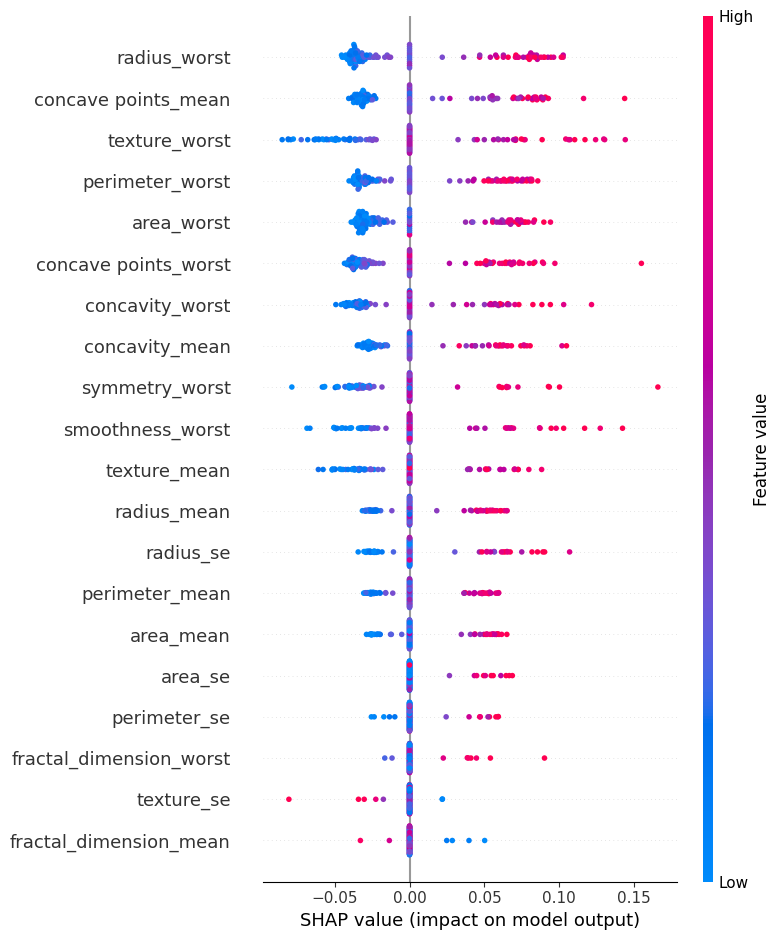

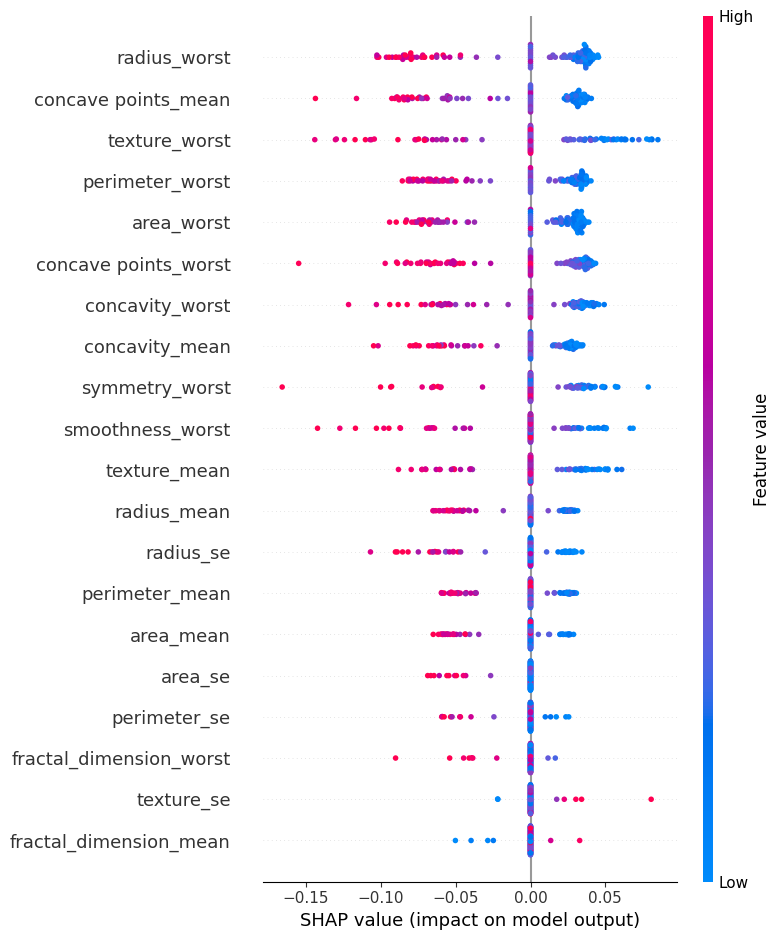

In [ ]:
import shap
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report

df = pd.read_csv('breast.csv')
df['diagnosis'] = LabelEncoder().fit_transform(df['diagnosis'])

X = df.drop(columns=['id', 'Unnamed: 32', 'diagnosis'], errors='ignore')
y = df['diagnosis']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
model = SVC(probability=True, random_state=42)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
print(classification_report(y_test, y_pred))

# --- SHAP Explanation ---
# SHAP KernelExplainer for non-tree models like SVM
explainer = shap.KernelExplainer(model.predict_proba, X_train_scaled[:100])  # use a subset for speed
shap_values = explainer.shap_values(X_test_scaled)  # also subset for speed
shap.summary_plot(shap_values[:, :, 1], X_test, feature_names=X.columns)
shap.summary_plot(shap_values[:, :, 0], X_test, feature_names=X.columns)


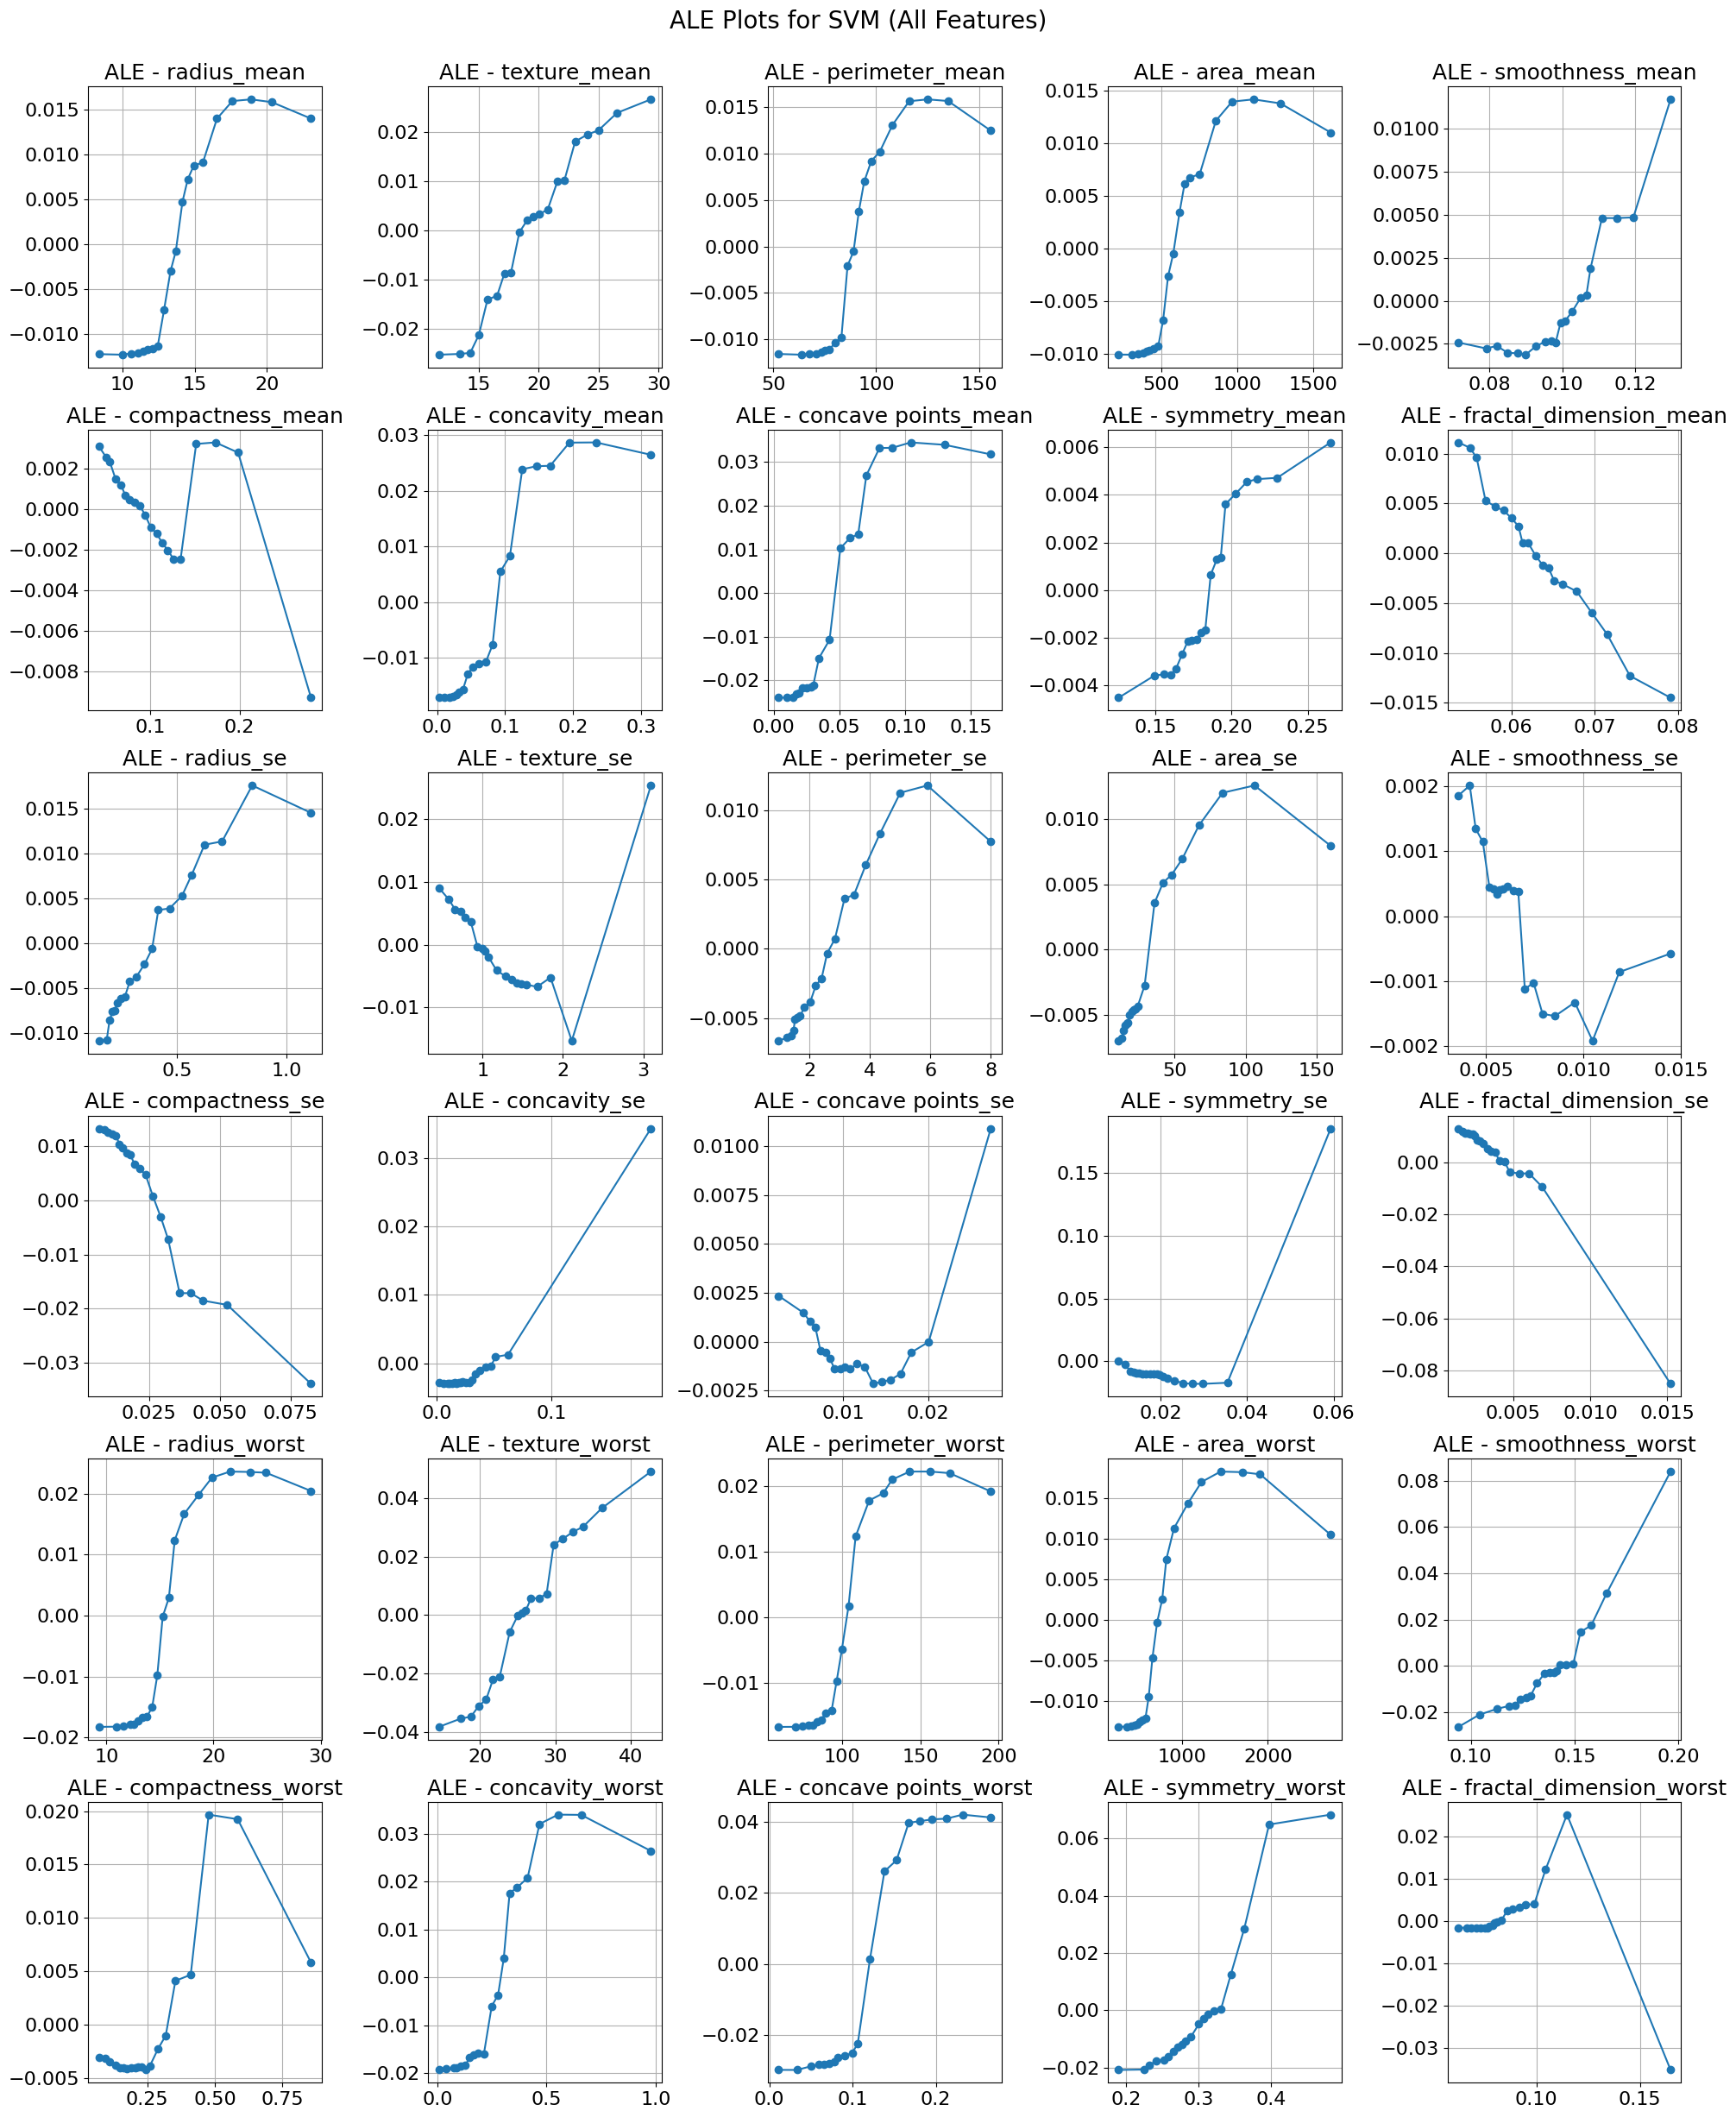

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ALE function
def ale(model, X, feature, bins=10):
    X = X.copy()
    X[feature] = X[feature].astype(float)
    use_proba = hasattr(model, "predict_proba")
    x = X[feature].values
    edges = np.quantile(x, np.linspace(0, 1, bins + 1))
    effects = np.zeros(bins)
    counts = np.zeros(bins)

    for j in range(bins):
        lo, hi = edges[j], edges[j + 1]
        mask = (x >= lo) & (x < hi) if j < bins - 1 else (x >= lo) & (x <= hi)
        if not mask.any():
            continue
        X_lo, X_hi = X.copy(), X.copy()
        X_lo[feature], X_hi[feature] = lo, hi
        if use_proba:
            p_lo = model.predict_proba(X_lo)[:, 1]
            p_hi = model.predict_proba(X_hi)[:, 1]
        else:
            p_lo = model.predict(X_lo).astype(float)
            p_hi = model.predict(X_hi).astype(float)
        diff = p_hi[mask] - p_lo[mask]
        effects[j] = diff.mean()
        counts[j] = mask.sum()

    cum = np.cumsum(effects)
    wm = (cum * counts).sum() / counts.sum()
    centers = (edges[:-1] + edges[1:]) / 2
    return centers, cum - wm

# Load and preprocess data
data = pd.read_csv("breast.csv")  # Update this path if needed
target = next((col for col in ["diagnosis", "status", "target"] if col in data.columns), None)
if target is None:
    raise ValueError("Target column not found.")

non_num = data.select_dtypes(include="object").columns.tolist()
if target in non_num:
    non_num.remove(target)
data = data.drop(columns=non_num)

X = data.drop(columns=[target])
y = data[target]
if y.dtype == "object":
    y = y.astype("category").cat.codes

X = X.dropna(axis=1, how="all")
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)
id_cols = [c for c in X.columns if "id" in c.lower()]
features = [f for f in X.columns if f not in id_cols]

# Train SVM model
model = Pipeline([
    ("imp", SimpleImputer()),
    ("scale", StandardScaler()),
    ("clf", SVC(probability=True, random_state=42))
])
model.fit(X_train, y_train)

# Plot all ALEs in a 4-column grid
n_feats = len(features)
ncols = 5
nrows = (n_feats + ncols - 1) // ncols

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(20, 4 * nrows))
axes = axes.flatten()

for i, feat in enumerate(features):
    centers, ale_vals = ale(model, X_test, feat, bins=20)
    ax = axes[i]
    ax.plot(centers, ale_vals, marker='o', linestyle='-')
    ax.set_title(f"ALE - {feat}", fontsize=18)
    # ax.set_xlabel(feat, fontsize=18)
    # ax.set_ylabel("ALE", fontsize=18)
    ax.tick_params(axis='both', which='major', labelsize=16)  # increase tick font
    ax.grid(True)

# Hide any unused subplot panels
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.suptitle("ALE Plots for SVM (All Features)", fontsize=20, y=1.02)
plt.show()


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score

from interpret.glassbox import ExplainableBoostingClassifier
from interpret import show

df = pd.read_csv('breast.csv')
df['diagnosis'] = LabelEncoder().fit_transform(df['diagnosis'])  # 1 = malignant

X = df.drop(columns=['id', 'Unnamed: 32', 'diagnosis'], errors='ignore')
y = df['diagnosis']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

ebm = ExplainableBoostingClassifier(random_state=42)
ebm.fit(X_train, y_train)

y_pred = ebm.predict(X_test)
print(classification_report(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))

ebm_global = ebm.explain_global()
show(ebm_global)


              precision    recall  f1-score   support

           0       0.97      0.97      0.97        71
           1       0.95      0.95      0.95        43

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114

Accuracy: 0.9649122807017544


# SVM LOCAL

              precision    recall  f1-score   support

           0       0.97      1.00      0.99        71
           1       1.00      0.95      0.98        43

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



  0%|          | 0/5 [00:00<?, ?it/s]

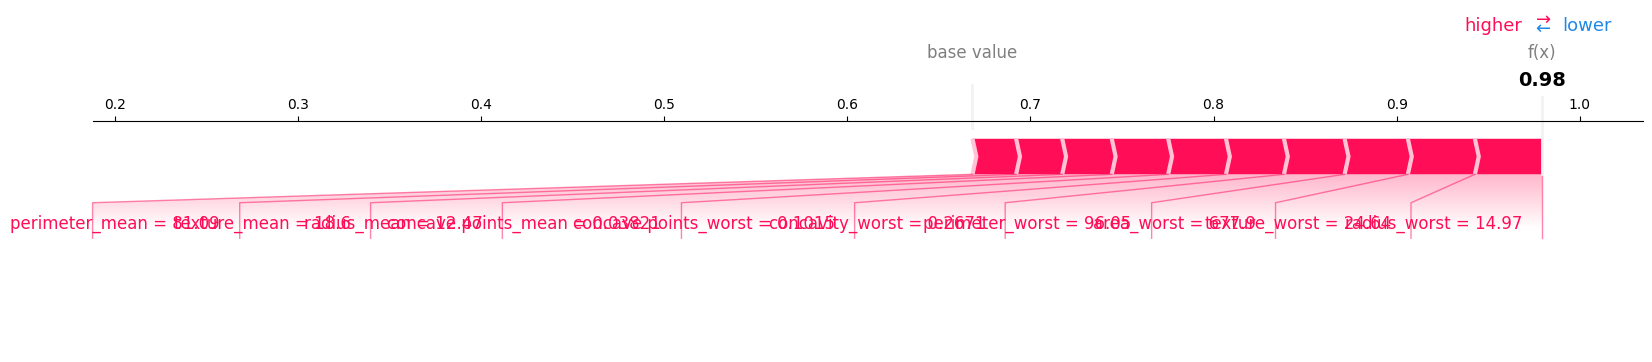

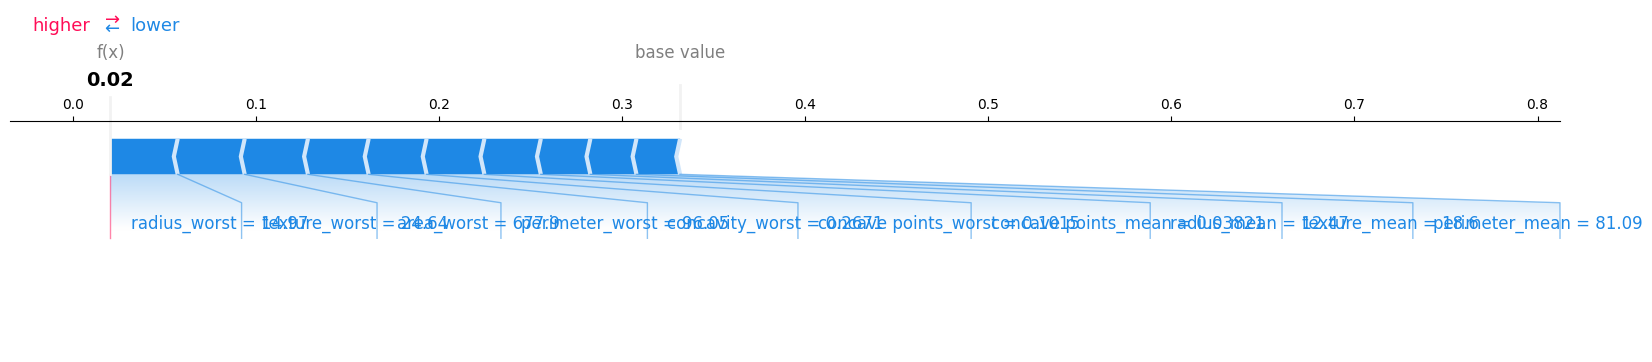

TypeError: The waterfall plot requires an `Explanation` object as the `shap_values` argument.

In [ ]:
import shap
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report

df = pd.read_csv('breast.csv')
df['diagnosis'] = LabelEncoder().fit_transform(df['diagnosis'])

X = df.drop(columns=['id', 'Unnamed: 32', 'diagnosis'], errors='ignore')
y = df['diagnosis']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns)

model = SVC(probability=True, random_state=42)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
print(classification_report(y_test, y_pred))

explainer = shap.KernelExplainer(model.predict_proba, X_train_scaled[:100])
shap_values = explainer.shap_values(X_test_scaled[:5])
shap_values_for_plot = shap_values[..., 0]
shap.force_plot(explainer.expected_value[0], shap_values_for_plot[0], X_test.iloc[0], feature_names=X.columns, matplotlib=True)
shap_values_for_plot = shap_values[..., 1]
shap.force_plot(explainer.expected_value[1], shap_values_for_plot[0], X_test.iloc[0], feature_names=X.columns, matplotlib=True)
shap_values = explainer(X_test_scaled)
shap.plots.waterfall(shap_values[0][:, 0])
shap.plots.waterfall(shap_values[30][:, 1])


  0%|          | 0/114 [00:00<?, ?it/s]

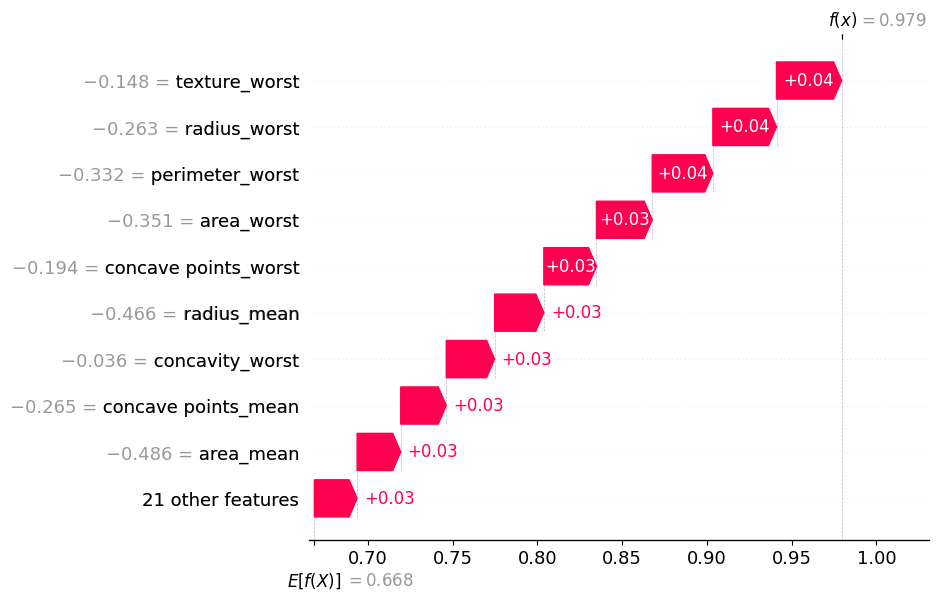

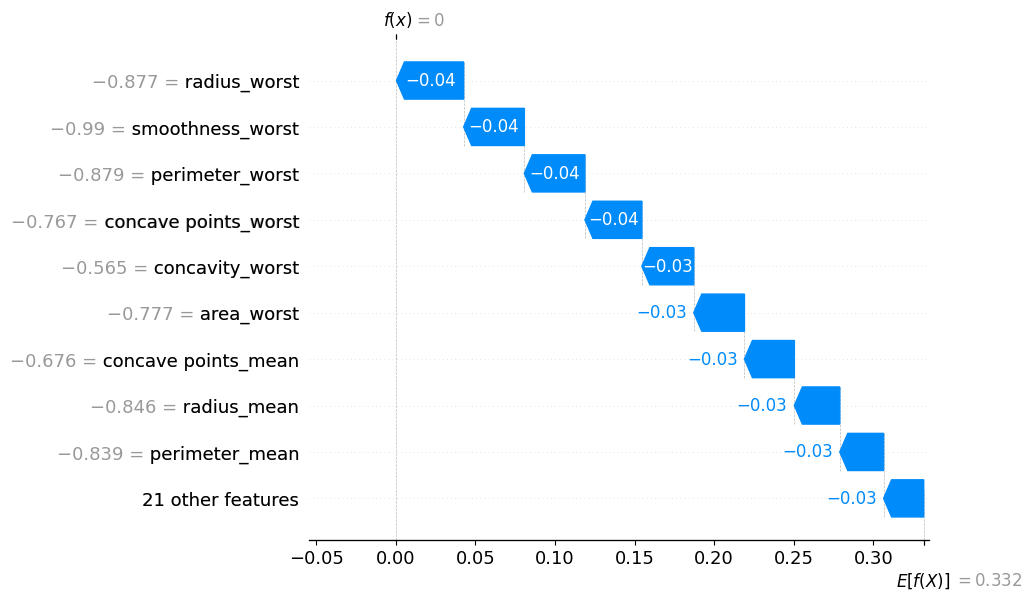

In [ ]:
shap_values = explainer(X_test_scaled)
shap.plots.waterfall(shap_values[0][:, 0])
shap.plots.waterfall(shap_values[30][:, 1])

In [ ]:
import shap
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report
import lime

df = pd.read_csv('breast.csv')
df['diagnosis'] = LabelEncoder().fit_transform(df['diagnosis'])

X = df.drop(columns=['id', 'Unnamed: 32', 'diagnosis'], errors='ignore')
y = df['diagnosis']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
model = SVC(probability=True, random_state=42)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.97      1.00      0.99        71
           1       1.00      0.95      0.98        43

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



                   precision    recall  f1-score   support

Non Breast Cancer       0.96      1.00      0.98        72
    Breast Cancer       1.00      0.93      0.96        42

         accuracy                           0.97       114
        macro avg       0.98      0.96      0.97       114
     weighted avg       0.97      0.97      0.97       114



/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(



LIME explanation (feature, weight):
  texture_worst <= 21.49          ->  -0.1495
  radius_worst <= 13.02           ->  -0.1057
  smoothness_worst > 0.15         ->  +0.0995
  area_worst <= 516.15            ->  -0.0905
  perimeter_worst <= 84.13        ->  -0.0894
  texture_mean <= 16.34           ->  -0.0866
  perimeter_mean <= 75.23         ->  -0.0734
  radius_mean <= 11.71            ->  -0.0681
  area_mean <= 420.40             ->  -0.0643
  radius_se <= 0.23               ->  -0.0633


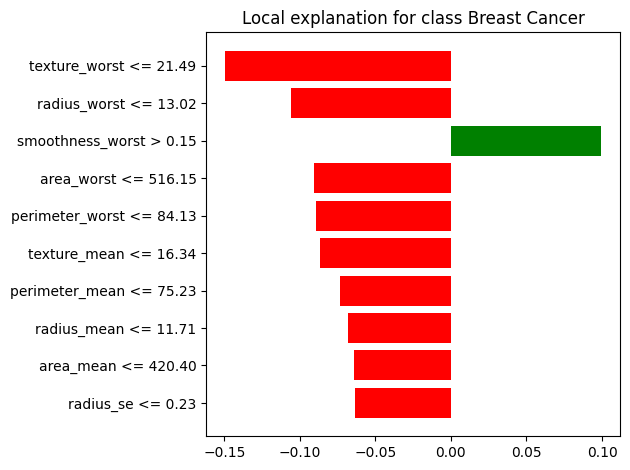

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import classification_report

import lime
from lime.lime_tabular import LimeTabularExplainer

# 1) Load & preprocess
df = pd.read_csv('breast.csv')
df['diagnosis'] = LabelEncoder().fit_transform(df['diagnosis'])  # 0=Benign,1=Malignant
X = df.drop(columns=['id','Unnamed: 32','diagnosis'], errors='ignore')
y = df['diagnosis']

# 2) Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 3) Build a pipeline that scales then SVM
pipeline = make_pipeline(
    StandardScaler(),
    SVC(probability=True, random_state=42)
)
pipeline.fit(X_train, y_train)

# 4) Evaluate
y_pred = pipeline.predict(X_test)
print(classification_report(
    y_test, y_pred,
    target_names=["Non Breast Cancer","Breast Cancer"]
))

# 5) Set up LIME explainer on *unscaled* training data
explainer = LimeTabularExplainer(
    training_data    = X_train.values,
    feature_names    = X.columns.tolist(),
    class_names      = ["Non Breast Cancer","Breast Cancer"],
    discretize_continuous = True,
    random_state     = 42
)

# 6) Choose an instance to explain
i = 0  # you can loop or pick any index in [0 .. len(X_test)-1]
x_raw = X_test.values[i]  # LIME wants the raw (unscaled) features

# 7) Generate explanation (top 10 local features)
exp = explainer.explain_instance(
    x_raw,
    pipeline.predict_proba,
    num_features = 10,   # you can increase or set to X_train.shape[1] for *all* features
    num_samples  = 5000
)

# 8) Print the local weights
print("\nLIME explanation (feature, weight):")
for feat, weight in exp.as_list():
    print(f"  {feat:30s}  ->  {weight:+.4f}")

# 9) Plot as a horizontal bar chart
fig = exp.as_pyplot_figure()
# plt.title(f"LIME Local Explanation for Test Instance {i}", pad=20)
plt.tight_layout()
plt.show()


In [ ]:
y_test.values[10]

np.int64(1)

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(



LIME explanation (feature, weight):
  concave points_mean > 0.07      ->  +0.1412
  symmetry_worst > 0.32           ->  +0.1294
  concavity_worst > 0.39          ->  +0.1217
  area_mean > 795.50              ->  +0.1203
  concave points_worst > 0.16     ->  +0.1158
  concavity_mean > 0.13           ->  +0.1158
  radius_mean > 15.93             ->  +0.1027
  perimeter_mean > 104.50         ->  +0.1025
  compactness_se > 0.03           ->  -0.0842
  fractal_dimension_se > 0.00     ->  -0.0578


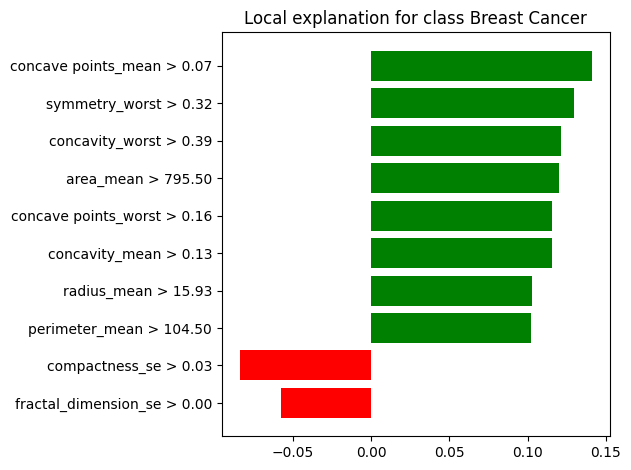

In [ ]:

i = 10  # you can loop or pick any index in [0 .. len(X_test)-1]
x_raw = X_test.values[i]  # LIME wants the raw (unscaled) features


exp = explainer.explain_instance(
    x_raw,
    pipeline.predict_proba,
    num_features = 10,
    num_samples  = 5000
)

print("\nLIME explanation (feature, weight):")
for feat, weight in exp.as_list():
    print(f"  {feat:30s}  ->  {weight:+.4f}")

fig = exp.as_pyplot_figure()
# plt.title(f"LIME Local Explanation for Test Instance {i}", pad=20)
plt.tight_layout()
plt.show()


#EBM

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score

from interpret.glassbox import ExplainableBoostingClassifier
from interpret import show

df = pd.read_csv('breast.csv')
df['diagnosis'] = LabelEncoder().fit_transform(df['diagnosis'])  # 1 = malignant

X = df.drop(columns=['id', 'Unnamed: 32', 'diagnosis'], errors='ignore')
y = df['diagnosis']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

ebm = ExplainableBoostingClassifier(random_state=42)
ebm.fit(X_train, y_train)

y_pred = ebm.predict(X_test)
print(classification_report(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))

# ebm_global = ebm.explain_global()
# show(ebm_global)
# Get local explanation for the first few test samples
ebm_local = ebm.explain_local(X_test[:5], y_test[:5])
show(ebm_local)


              precision    recall  f1-score   support

           0       0.97      0.97      0.97        71
           1       0.95      0.95      0.95        43

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114

Accuracy: 0.9649122807017544


In [ ]:
ebm_local = ebm.explain_local(X_test[:5], y_test[:5])
show(ebm_local)

In [ ]:
sample_idx = 0
ebm_local = ebm.explain_local(X_test[sample_idx:sample_idx+1], y_test[sample_idx:sample_idx+1])
show(ebm_local)
